In [1]:
from config_path import add_to_sys_path
add_to_sys_path()  # Call the function to add path

import numpy as np
from sympy.physics.wigner import wigner_3j,wigner_6j
import sympy as sy
from numpy import linalg as LA
from IPython.display import Latex,display
import matplotlib.pyplot as plt
from matplotlib import colors
%matplotlib inline
import seaborn as sns
sns.set()
sns.set_palette('bright')
from Energy_Levels import MoleculeLevels
from Energy_Levels import branching_ratios, Calculate_TDMs,Calculate_TDM_evecs
from functools import partial
np.set_printoptions(precision=5, suppress=True)
from tabulate import tabulate
from matplotlib.collections import LineCollection

Added C:\Users\Arian\Code\Molecule-Structure\Source Code to sys.path


In [2]:
%matplotlib inline

In [3]:
N_list = [1]
print(N_list)

[1]


In [4]:
# X010 = MoleculeLevels.initialize_state('CaOH','40','X010',N_list,M_values = 'custom',I=[0,1/2],S=1/2,round=16,M_range=[1])
# port 2026-10-25: old positional (molecule, isotope, vibronic) -> (molecule, elec_state, vib_state) + fermion/isotope kwargs;
# M_values -> M_sublevels, I -> I_nuclei, S -> S_electron. Same state: 173YbOH X(010), N=1, I=[5/2,1/2], M>=0, P=1/2,3/2.
X010 = MoleculeLevels.initialize_state('YbOH','X','010',N_list,fermion_or_boson='fermion',isotope='173',M_sublevels = 'pos',I_nuclei=[5/2,1/2],S_electron=1/2,round=8,P_values=[1/2,3/2])

In [5]:
B0 = 1e-1
E0 = 500
evals, evecs = X010.eigensystem(E0,B0,order=True,method='torch')

Text(0.5, 1.0, '$^{173}$YbOH ${X}({010})$, G=2, N=1, E=100 V/cm, B=0.1 G')

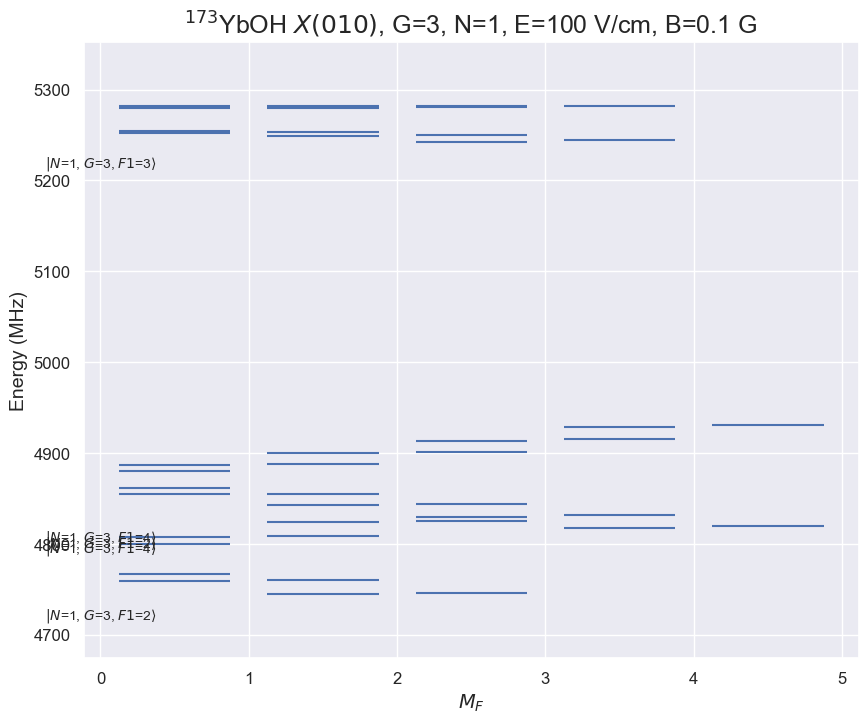

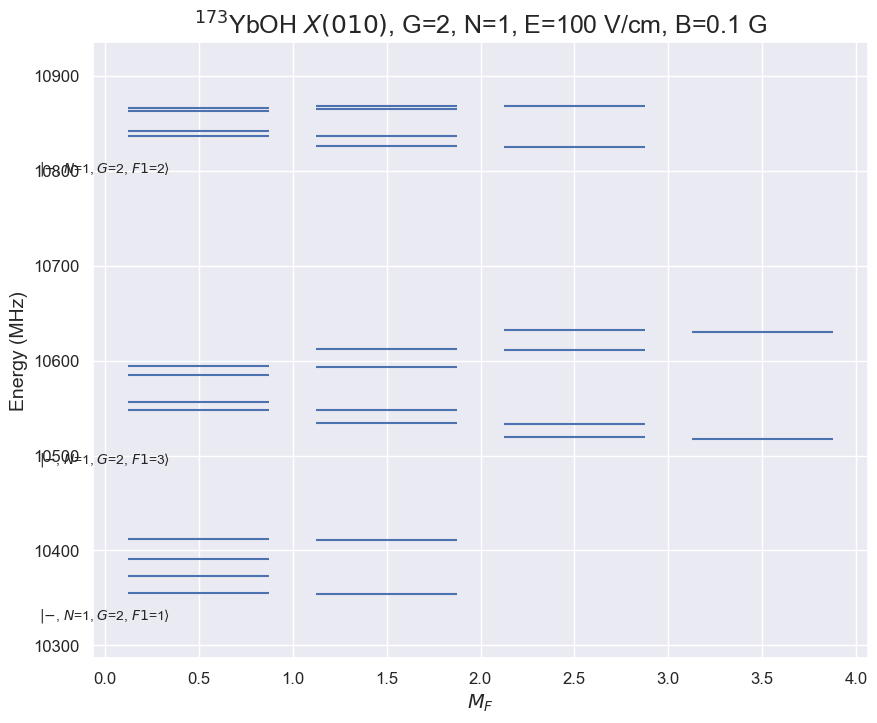

In [6]:
B0 = 1e-1
E0 = 100

G=3
X010.display_levels(E0,B0,'F1',idx=X010.select_q({'G':G}),parity=False,label_q=[q for q in X010.q_str if q not in ['F','K']],label_off=0.05,figsize=(10,8),alt_label=False)
plt.title(X010.state_str+', G={}, N=1, E={} V/cm, B={} G'.format(G,E0,B0),fontsize=18)
# plt.grid(False)
# ax = plt.gca()
# ax.set_facecolor('None')
# plt.ylim(9300,9400)
# plt.ylim(35500,36000)

G=2
X010.display_levels(E0,B0,'F1',idx=X010.select_q({'G':G}),parity=True,label_q=[q for q in X010.q_str if q not in ['F','K']],label_off=0.05,figsize=(10,8),alt_label=False)
plt.title(X010.state_str+', G={}, N=1, E={} V/cm, B={} G'.format(G,E0,B0),fontsize=18)
# ax = plt.gca()
# ax.set_facecolor('None')
# plt.grid(False)

In [7]:
B0 = 1e-3
E0 = 10
evals, evecs = X010.eigensystem(E0,B0,order=True,method='torch')
M0_idx = X010.select_q({'N':1,'G':2})
print(M0_idx)
print('\n')
for i in M0_idx:
    if X010.evals0[i]<100500:
        display(Latex('$E = '+str(np.round(X010.evals0[i],4))+r'\:\mathrm{MHz}$'))
        # port: decoupled-basis display disabled. convert_evecs('decoupled') from case bBS uses the single-nucleus
        # decoupler (molecule_library_class.py 'b_decoupled', commented 'WILL NOT WORK for case bBS'): KeyError 'M_I'.
        # print('Decoupled:')
        # display(Latex(X010.gen_state_str(i,basis='decoupled',thresh=0.05,label_q=['K','M_N','M_S','M_I','M_F'],round=4)))
    #     print('Case A:')
    #     display(Latex(X010.gen_state_str(i,basis='aBJ',thresh=0.05,label_q=['K','J','F','Sigma','P','M'],round=4)))
        print('Case B:')
        print('Parity=',X010.parities[i])
        display(Latex(X010.gen_state_str(i,thresh=0.0005,round=4)))
        print('\n')

[42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65
 66 67 68 69 70 71]




<IPython.core.display.Latex object>

Case B:
Parity= -1.0


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Case B:
Parity= -1.0


... (81 outputs left out)

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Case B:
Parity= 1.0


<IPython.core.display.Latex object>

In [8]:
Bz = np.linspace(1e-3,100,1000)
Ez = np.linspace(0,100,1000)

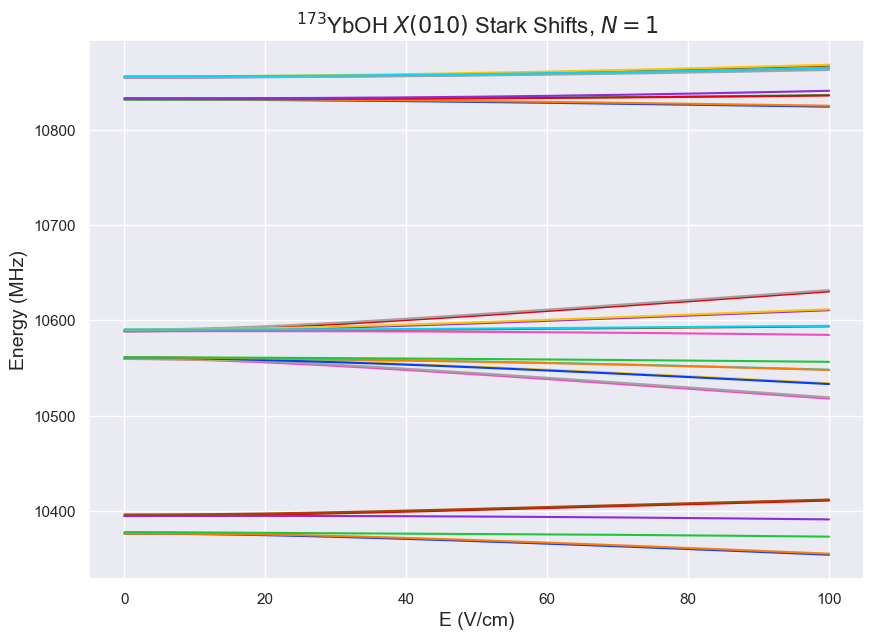

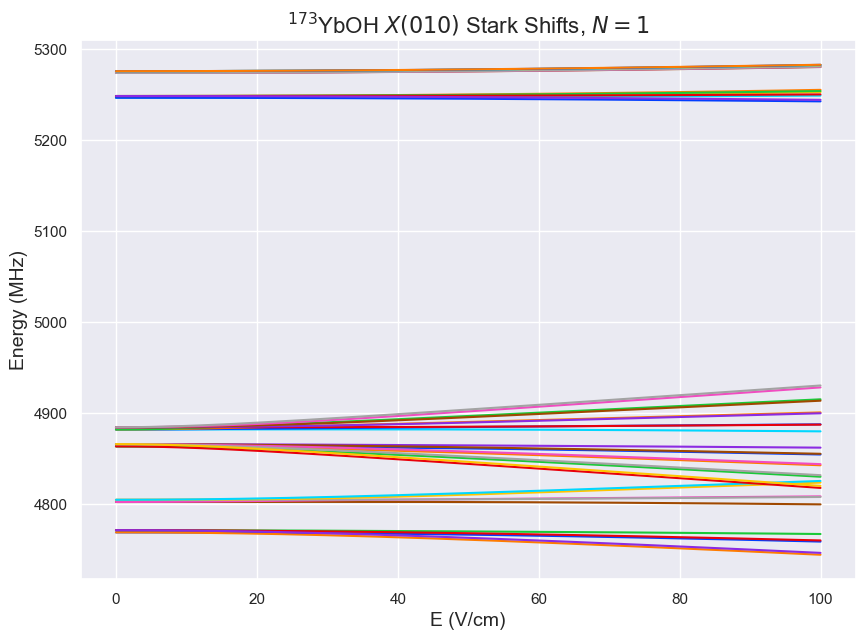

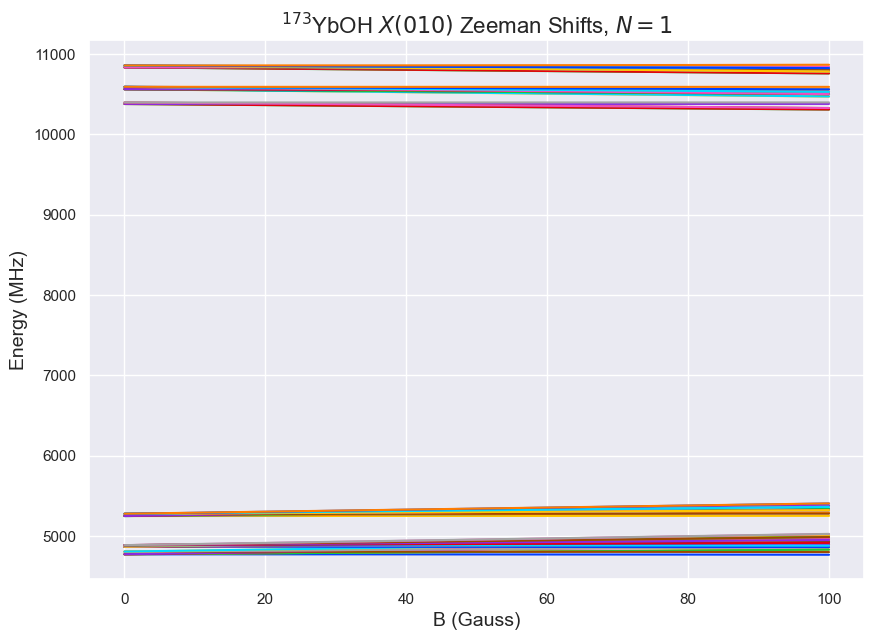

In [9]:
X010.StarkMap(Ez,1e-3,plot=True,idx=X010.select_q({'G':[2]}))
X010.StarkMap(Ez,1e-3,plot=True,idx=X010.select_q({'G':[3]}))
X010.ZeemanMap(Bz,0,plot=True)

In [10]:
from hamiltonian_builders import build_operator
from matrix_elements import StarkZ_bBS
from matrix_elements import ZeemanZ_bBS
from matrix_elements import EDM_bBS
from matrix_elements import MQM_bBS
from functools import partial

In [11]:
d_010 = build_operator(X010.q_numbers,X010.q_numbers,partial(StarkZ_bBS,I=X010.I_spins[0],iH=X010.I_spins[-1]))
mu_010 = build_operator(X010.q_numbers,X010.q_numbers,partial(ZeemanZ_bBS,I=X010.I_spins[0],iH=X010.I_spins[-1]))
EDM_010 = build_operator(X010.q_numbers,X010.q_numbers,partial(EDM_bBS, I=X010.I_spins[0],iH=X010.I_spins[-1]))
MQM_010 = np.sqrt(20/3)*1/(2*5/2*(2*5/2-1))*build_operator(X010.q_numbers,X010.q_numbers,partial(MQM_bBS, I=X010.I_spins[0],iH=X010.I_spins[-1]))

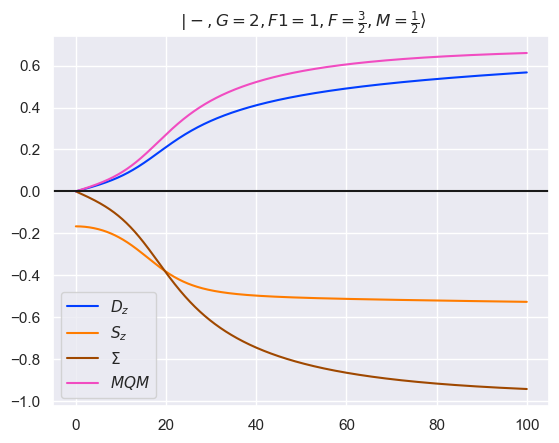

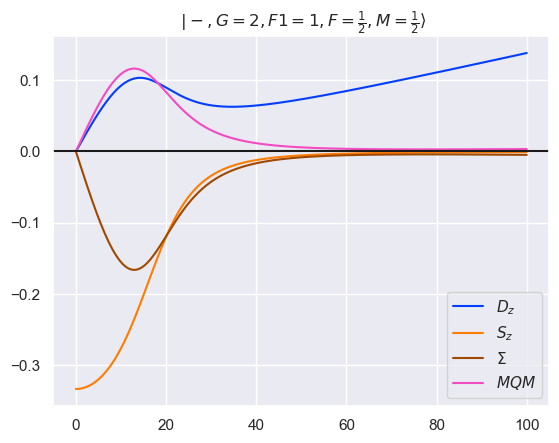

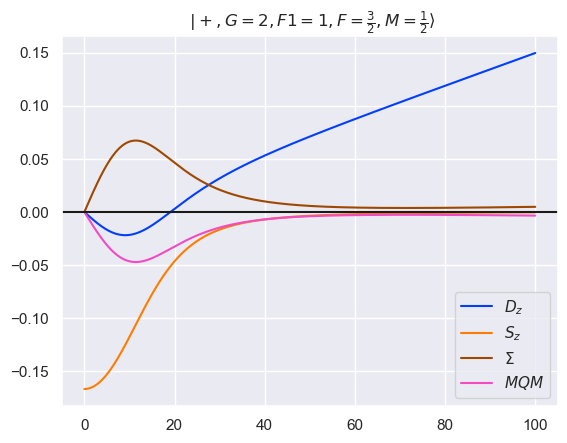

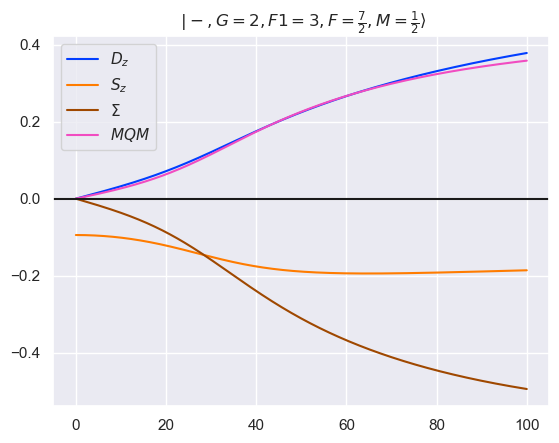

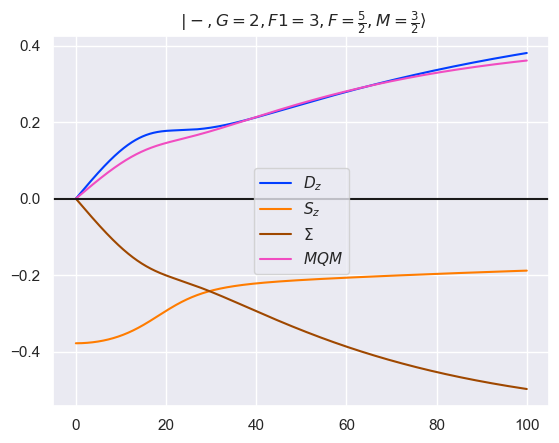

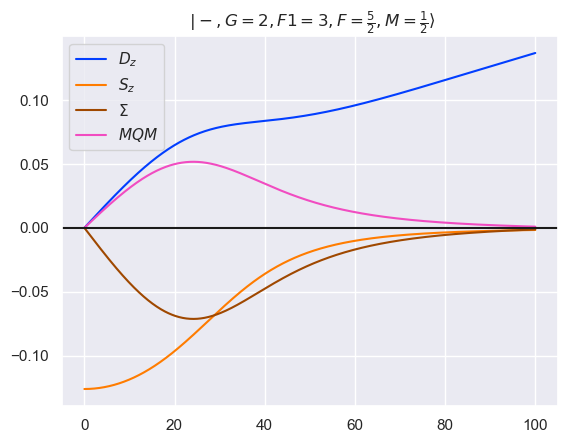

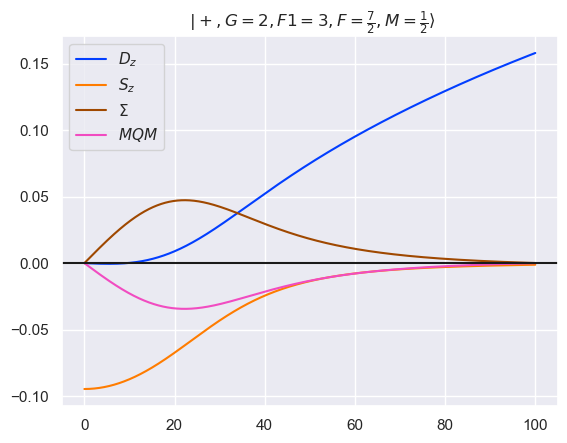

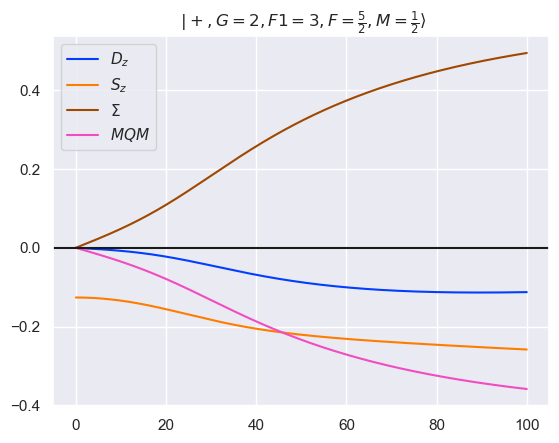

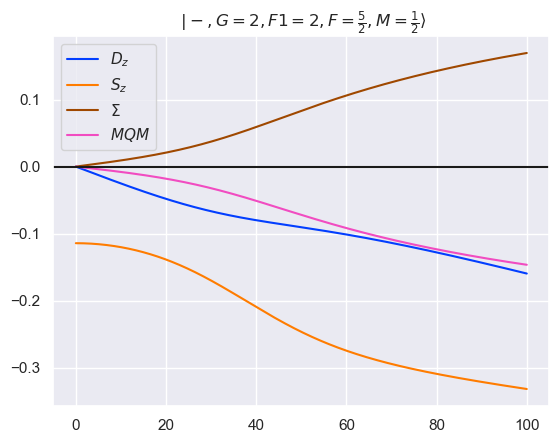

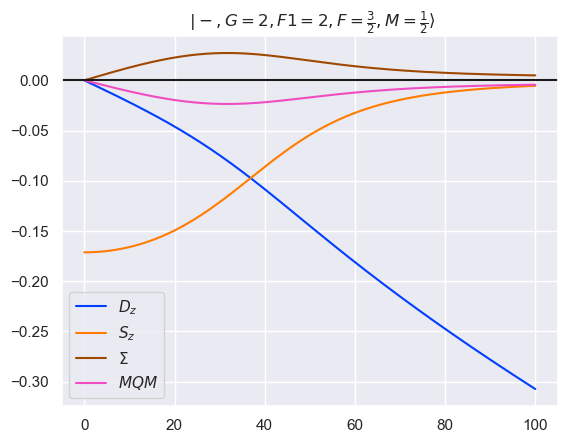

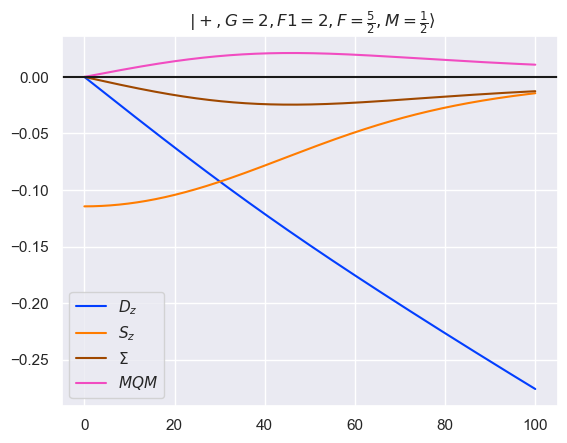

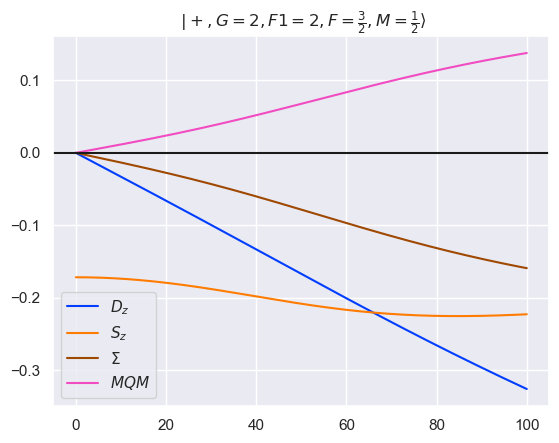

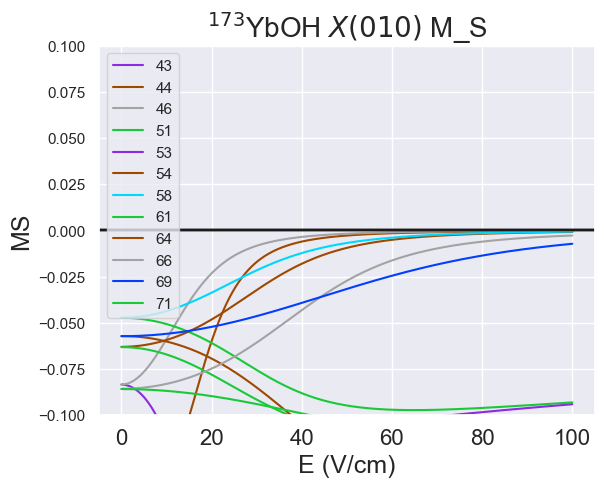

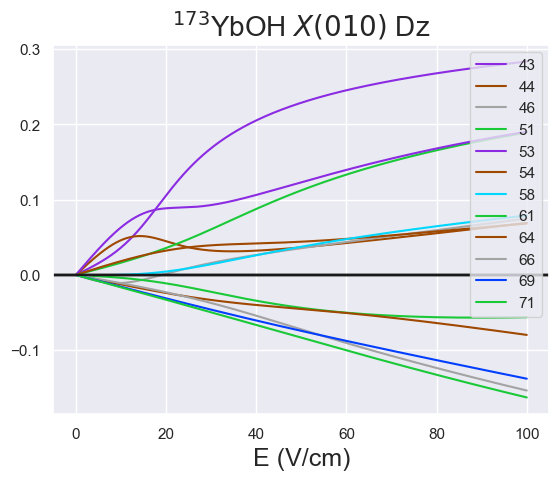

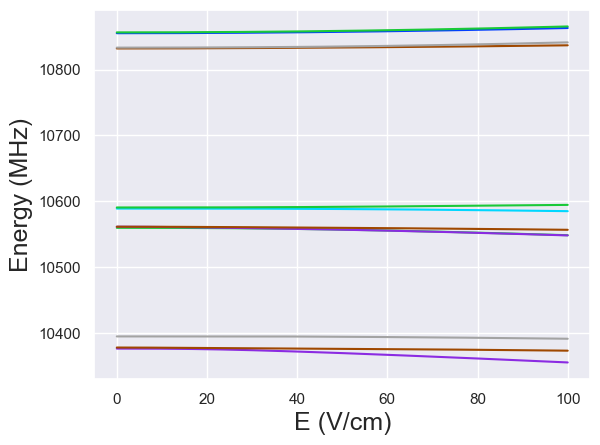

In [12]:
state = X010
Ez010 = Ez
state.eigensystem(0,1e-3)
# plt.figure(figsize=(7,3))
# alpha=0.2
plt.figure('All Sz')
plt.xlabel('E (V/cm)',fontsize=18)
plt.ylabel('MS',fontsize=18)
plt.title(state.state_str + ' M_S',fontsize=20)
plt.xticks(fontsize=16);
plt.ylim(-0.1,0.1)
# plt.ylim(-0.1,0.1)
plt.figure('Energies')
plt.xlabel('E (V/cm)',fontsize=18)
plt.ylabel('Energy (MHz)',fontsize=18)
plt.figure('All Dz')
plt.title(state.state_str + ' Dz',fontsize=20)
plt.xlabel('E (V/cm)',fontsize=18)
for i in state.select_q({'N':[1],'G':[2]}):
    Dz = np.diagonal(state.evecs_E[:,i,:]@d_010@state.evecs_E[:,i,:].T)
    Sz = np.diagonal(state.evecs_E[:,i,:]@mu_010@state.evecs_E[:,i,:].T)
    EDM = np.diagonal(state.evecs_E[:,i,:]@EDM_010@state.evecs_E[:,i,:].T)
    MQM = np.diagonal(state.evecs_E[:,i,:]@MQM_010@state.evecs_E[:,i,:].T)
    idx0 = abs(Sz)<0.1
    if np.any(idx0)==False:
#         print('Nope')
        continue
    else:
        plt.figure('Dz'+str(i))
        plt.title(X010.gen_state_str(i,parity=True,single=True,show_coeff=False,label_q=['G','F1','F','M']))
        plt.plot(Ez010,Dz/(1/2),label=r'$D_z$')
        plt.plot(Ez010,Sz/(1/2),label=r'$S_z$')
        plt.plot(Ez010,EDM/(1/4),label=r'$\Sigma$',color='C5')
        plt.plot(Ez010,MQM/(1/3),label=r'$MQM$',color='C6')
        plt.axhline(y=0,color='k')
        plt.legend(loc='best')
        
        plt.figure('All Sz')
#         mean = 10025
#         plt.plot(Ez010,(state.evals_E[:,i].T-mean)/1000,color='C'+str(i))
        
        plt.plot(Ez010,Sz,color='C'+str(i+1),label=i)
        plt.axhline(y=0,color='k')
        plt.legend(loc='best')
        
        plt.figure('All Dz')
#         mean = 10025
#         plt.plot(Ez010,(state.evals_E[:,i].T-mean)/1000,color='C'+str(i))
        
        plt.plot(Ez010,Dz,color='C'+str(i+1),label=i)
        plt.axhline(y=0,color='k')
        plt.legend(loc='best')
        
        plt.figure('Energies')
        plt.plot(Ez010,state.evals_E[:,i].T,color='C'+str(i+1))
# plt.axvline(62,color='black',linestyle='--')
# plt.yticks([-1,-0.5,0,0.5,1],fontsize=16);
# plt.tight_layout()
# plt.savefig('CaOH_N1_gfactor_vsE.svg',bbox_inches='tight')
# plt.xlim(300,350)
# plt.ylim(-0.1,0.1)
# plt.ylim(-0.1,0.1)

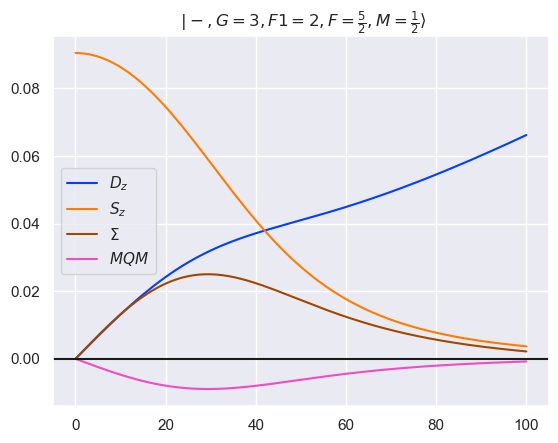

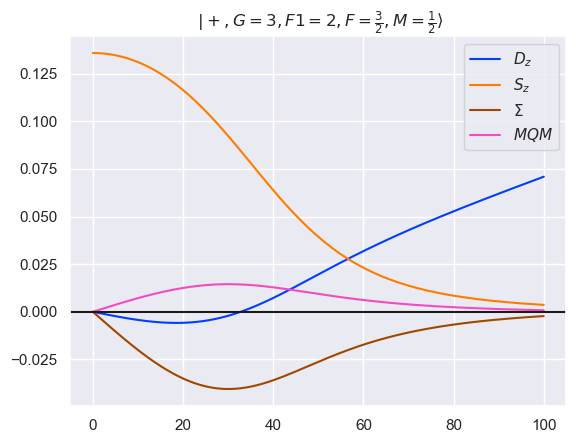

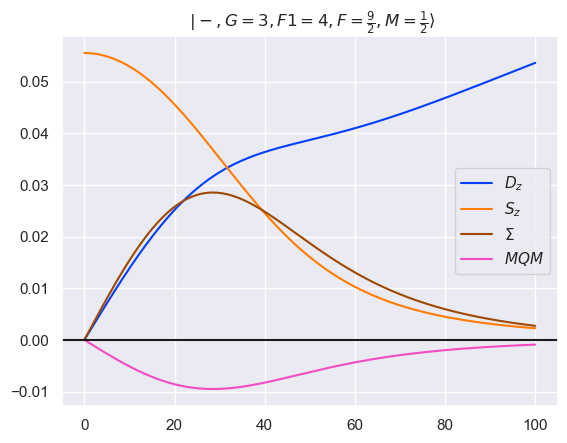

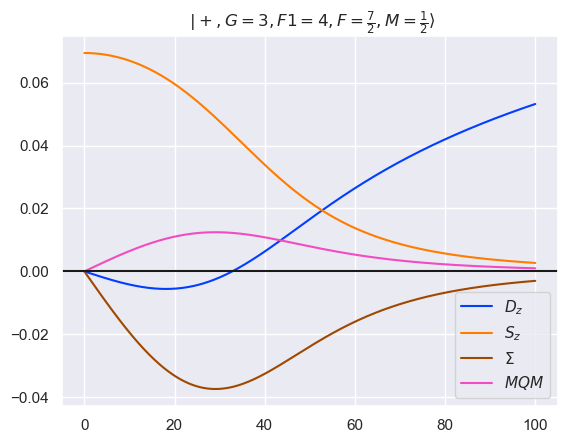

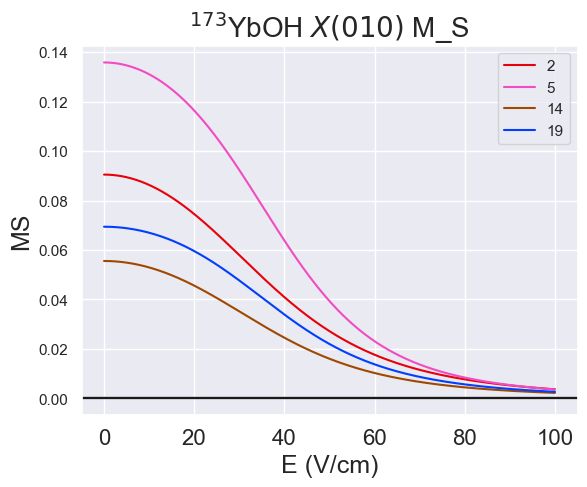

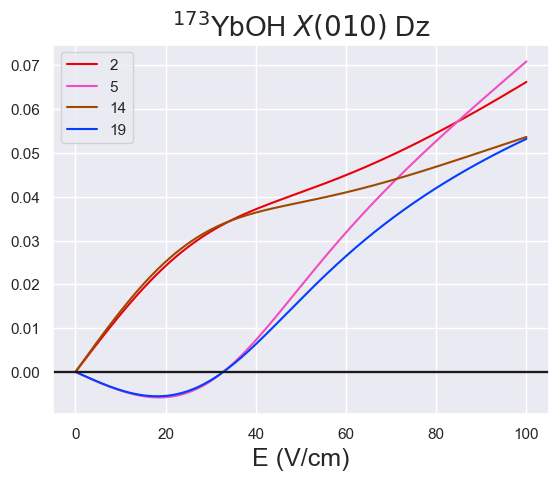

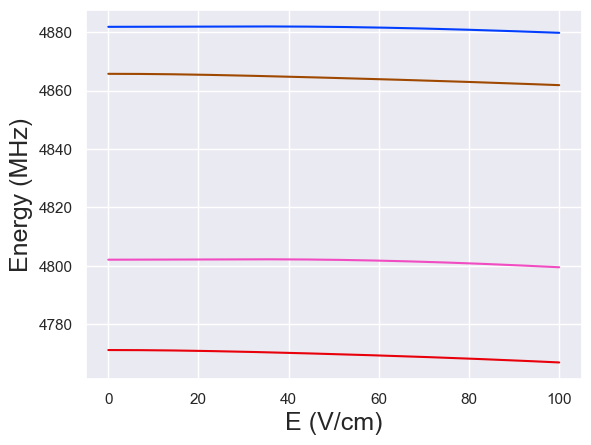

In [13]:
state = X010
Ez010 = Ez
state.eigensystem(0,1e-3)
# plt.figure(figsize=(7,3))
# alpha=0.2
plt.figure('All Sz')
plt.xlabel('E (V/cm)',fontsize=18)
plt.ylabel('MS',fontsize=18)
plt.title(state.state_str + ' M_S',fontsize=20)
plt.xticks(fontsize=16);
# plt.ylim(-0.1,0.1)
plt.figure('Energies')
plt.xlabel('E (V/cm)',fontsize=18)
plt.ylabel('Energy (MHz)',fontsize=18)
plt.figure('All Dz')
plt.title(state.state_str + ' Dz',fontsize=20)
plt.xlabel('E (V/cm)',fontsize=18)
for i in state.select_q({'N':[1],'G':[3]}):
    Dz = np.diagonal(state.evecs_E[:,i,:]@d_010@state.evecs_E[:,i,:].T)
    Sz = np.diagonal(state.evecs_E[:,i,:]@mu_010@state.evecs_E[:,i,:].T)
    EDM = np.diagonal(state.evecs_E[:,i,:]@EDM_010@state.evecs_E[:,i,:].T)
    MQM = np.diagonal(state.evecs_E[:,i,:]@MQM_010@state.evecs_E[:,i,:].T)
    idx0 = abs(Sz)<0.01
    if np.any(idx0)==False:
#         print('Nope')
        continue
    else:
        plt.figure('Dz'+str(i))
        plt.title(X010.gen_state_str(i,parity=True,single=True,show_coeff=False,label_q=['G','F1','F','M']))
        plt.plot(Ez010,Dz,label=r'$D_z$')
        plt.plot(Ez010,Sz,label=r'$S_z$')
        plt.plot(Ez010,EDM,label=r'$\Sigma$',color='C5')
        plt.plot(Ez010,MQM,label=r'$MQM$',color='C6')
        plt.axhline(y=0,color='k')
        plt.legend(loc='best')
        
        plt.figure('All Sz')
#         mean = 10025
#         plt.plot(Ez010,(state.evals_E[:,i].T-mean)/1000,color='C'+str(i))
        
        plt.plot(Ez010,Sz,color='C'+str(i+1),label=i)
        plt.axhline(y=0,color='k')
        plt.legend(loc='best')
        
        plt.figure('All Dz')
#         mean = 10025
#         plt.plot(Ez010,(state.evals_E[:,i].T-mean)/1000,color='C'+str(i))
        
        plt.plot(Ez010,Dz,color='C'+str(i+1),label=i)
        plt.axhline(y=0,color='k')
        plt.legend(loc='best')
        
        plt.figure('Energies')
        plt.plot(Ez010,state.evals_E[:,i].T,color='C'+str(i+1))
# plt.axvline(62,color='black',linestyle='--')
# plt.yticks([-1,-0.5,0,0.5,1],fontsize=16);
# plt.tight_layout()
# plt.savefig('CaOH_N1_gfactor_vsE.svg',bbox_inches='tight')
# plt.xlim(300,350)
# plt.ylim(-0.1,0.1)
# plt.ylim(-0.1,0.1)

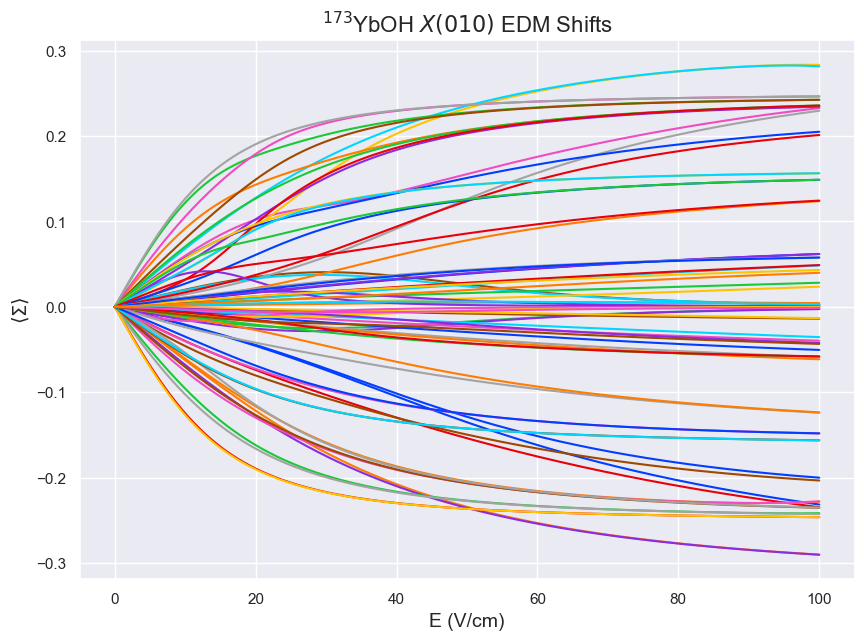

In [14]:
X010.PTV_Map('EDM',E_or_B='E',plot=True)

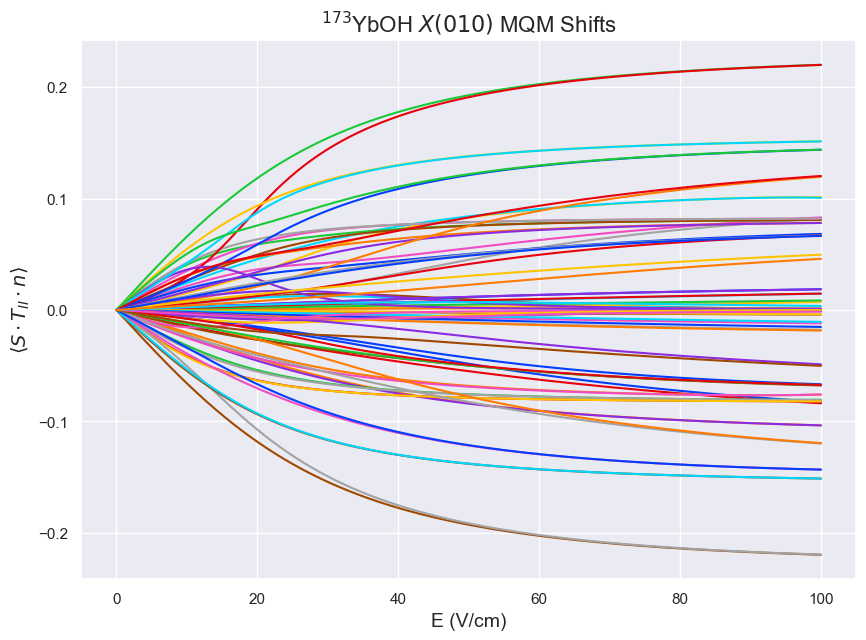

In [15]:
X010.PTV_Map('MQM',E_or_B='E',plot=True)

In [16]:
X010.g_eff_Map(step=1e-5);

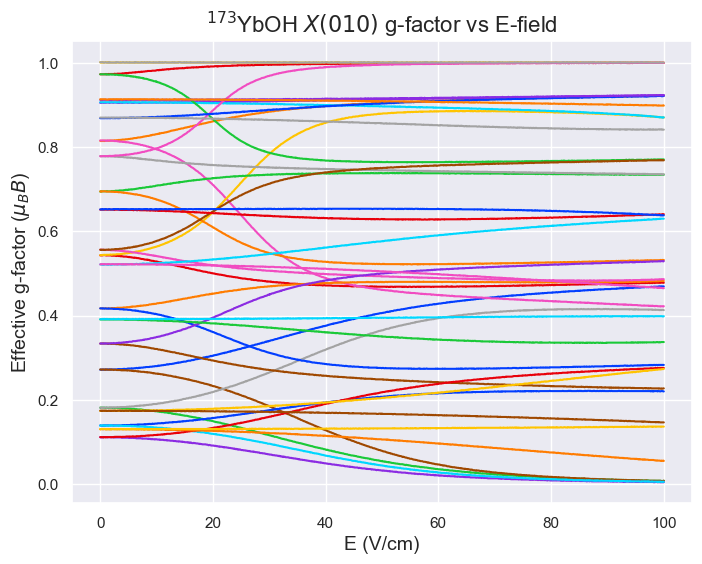

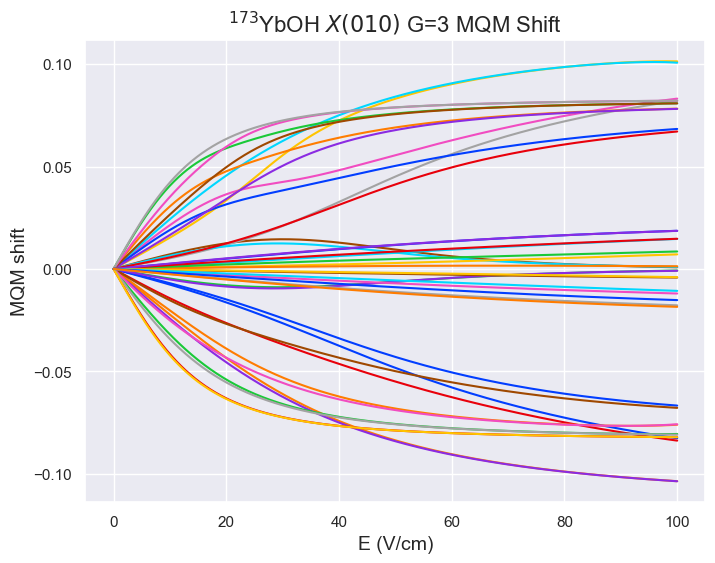

In [17]:
qd={'G':3}
plt.figure(figsize=(8,6))
for i in X010.select_q(qd):#range(len(X010_174.g_eff_E.T)):
#     if abs(X010.PTV_E.T[i]).mean()<0.05:
#         continue
    plt.plot(Ez,X010.g_eff_E.T[i])
plt.xlabel('E (V/cm)',fontsize=14)
plt.ylabel(r'Effective g-factor ($\mu_B B$)',fontsize=14)
plt.title(X010.state_str + ' g-factor vs E-field',fontsize=16);
plt.figure(figsize=(8,6))
for i in X010.select_q(qd):#range(len(X010_174.PTV_E.T)):
#     if abs(X010.PTV_E.T[i]).mean()<0.05:
#         continue
    plt.plot(Ez,X010.PTV_E.T[i])
plt.xlabel('E (V/cm)',fontsize=14)
plt.ylabel('MQM shift',fontsize=14)
plt.title(X010.state_str+' G={}'.format(qd['G'][0])+' MQM Shift',fontsize=16);

In [18]:
for i in X010.select_q(qd):#range(len(X010_174.PTV_E.T)):
#     if abs(X010.PTV_E.T[i]).mean()<0.05:
#         continue
    print(X010.PTV_E.T[i][-1])  # no *2: the library MQM now equals the FDK MQM_010 convention (MS 6c454d6)

-0.08268113
-0.10362708
-0.00078394
-0.08381182
-0.10365291
0.00079986
0.0831398
0.08205064
0.10133724
0.10067092
-0.06671318
-0.07605529
-0.08056751
-0.08214913
-0.00091172
-0.0678291
-0.07584142
-0.08095427
-0.08215282
0.00099328
0.06834126
0.0782385
0.0808458
0.06708704
0.07813322
0.08081774
0.082148
0.08215282
0.00710539
0.01463759
0.01861389
0.00131211
0.00851601
0.01472773
0.0185916
-0.00422365
-0.01200258
-0.01776366
-0.00401188
-0.0107108
-0.01521649
-0.01850107


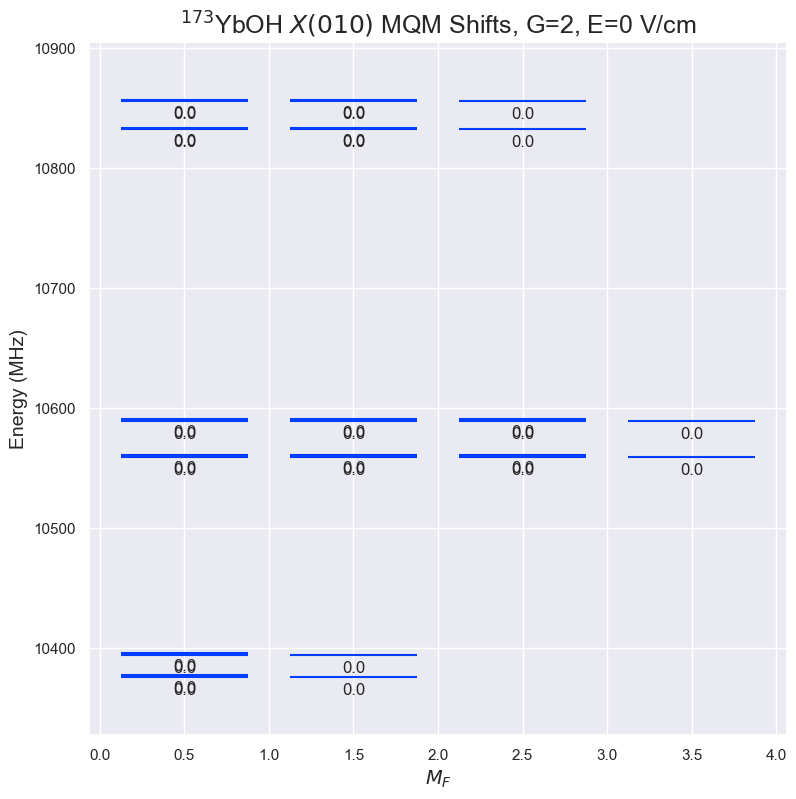

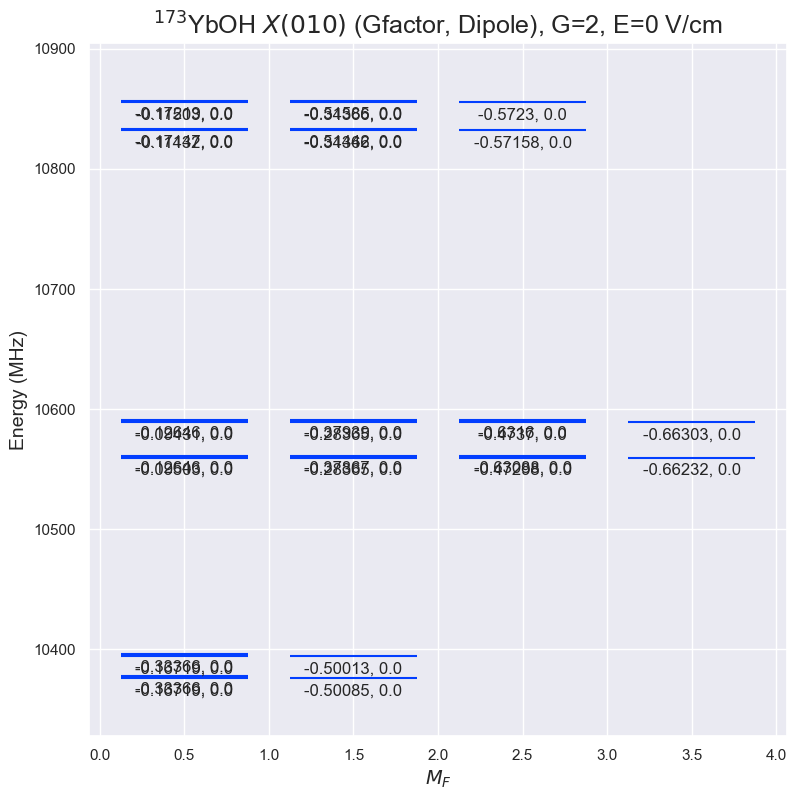

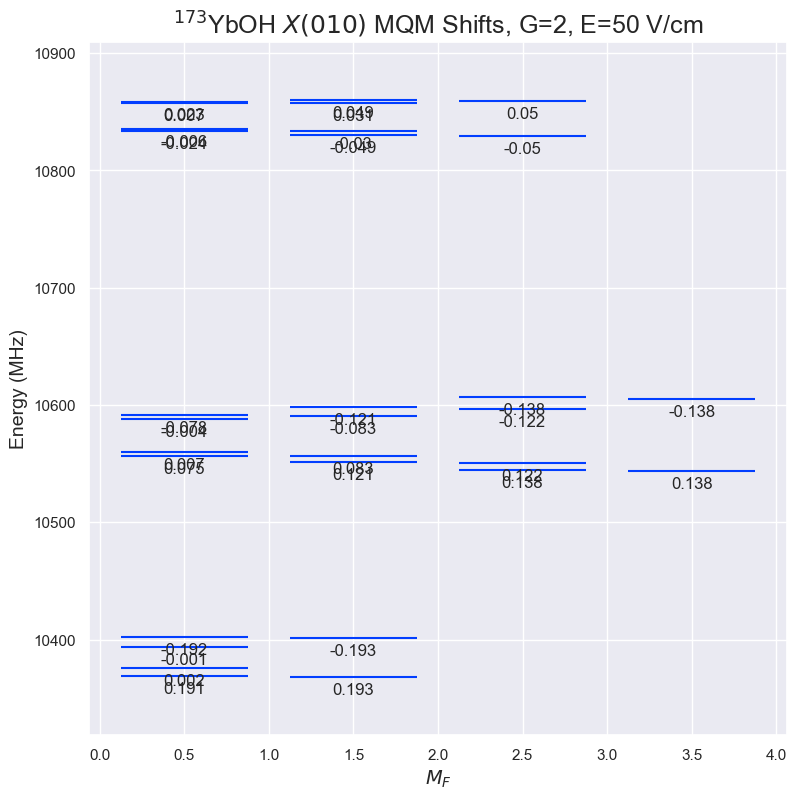

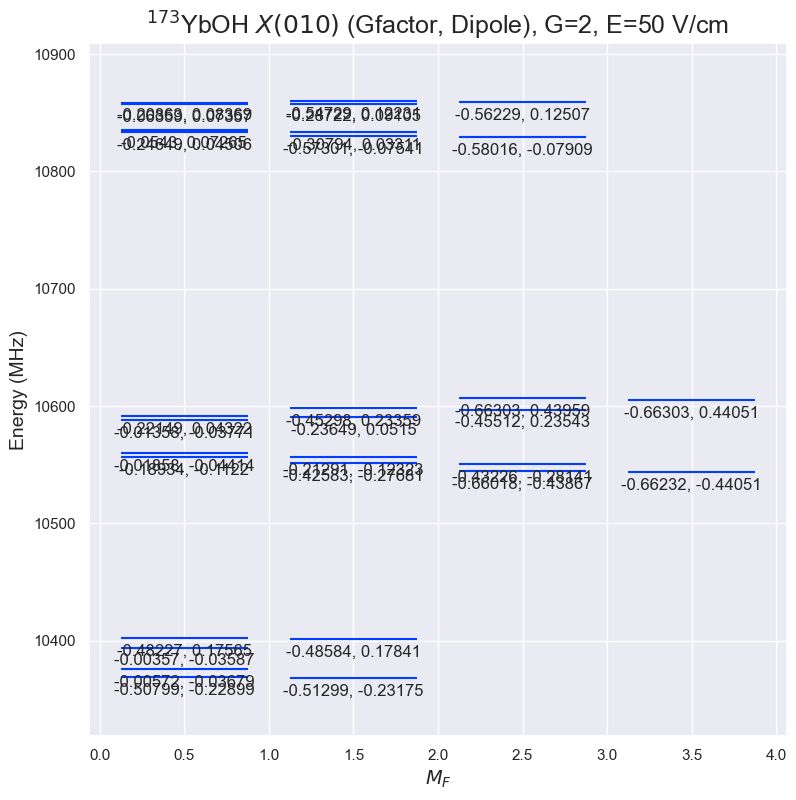

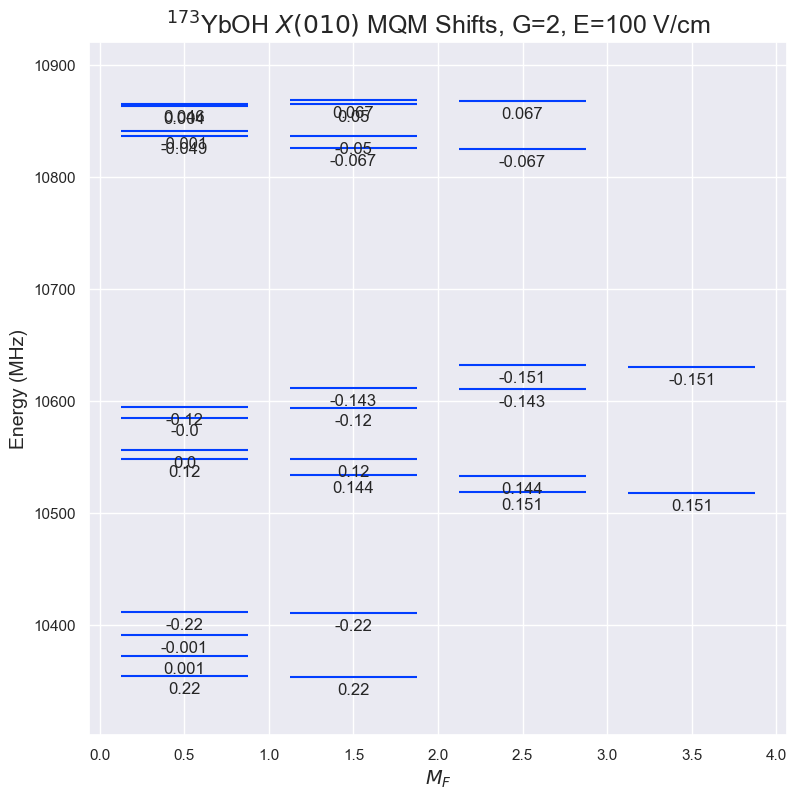

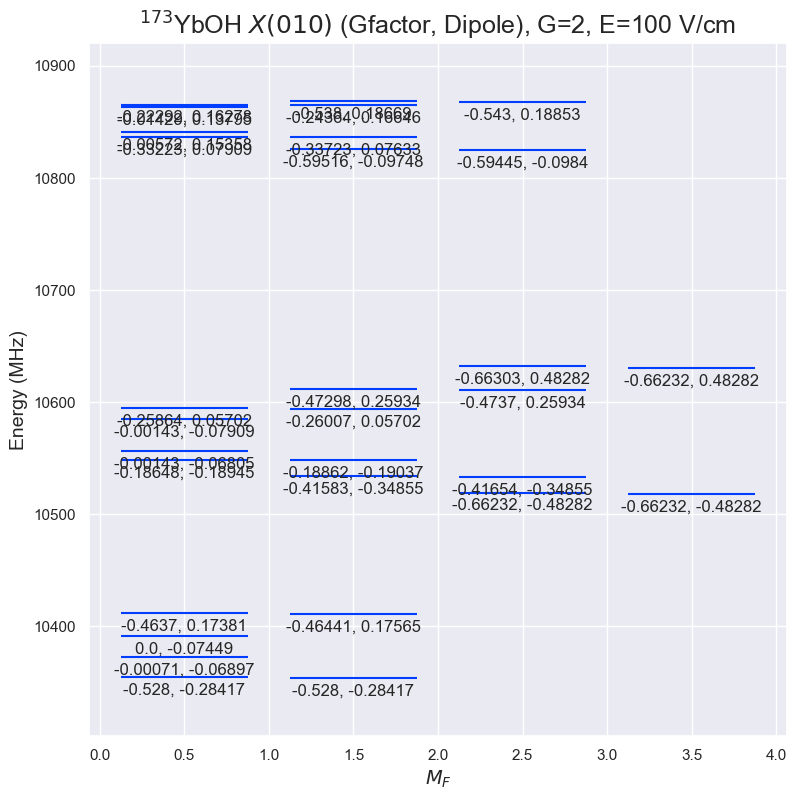

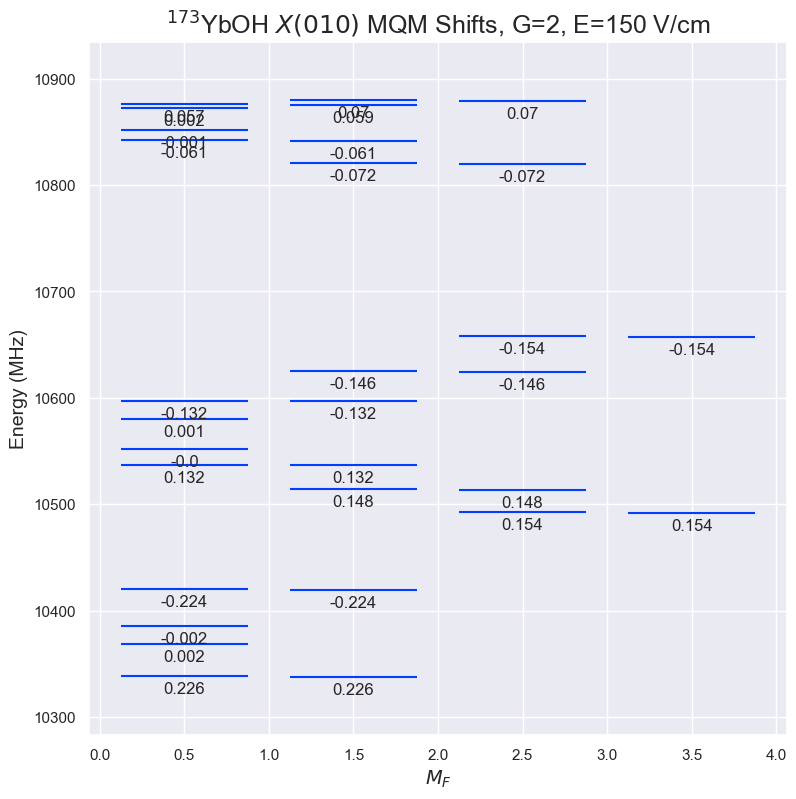

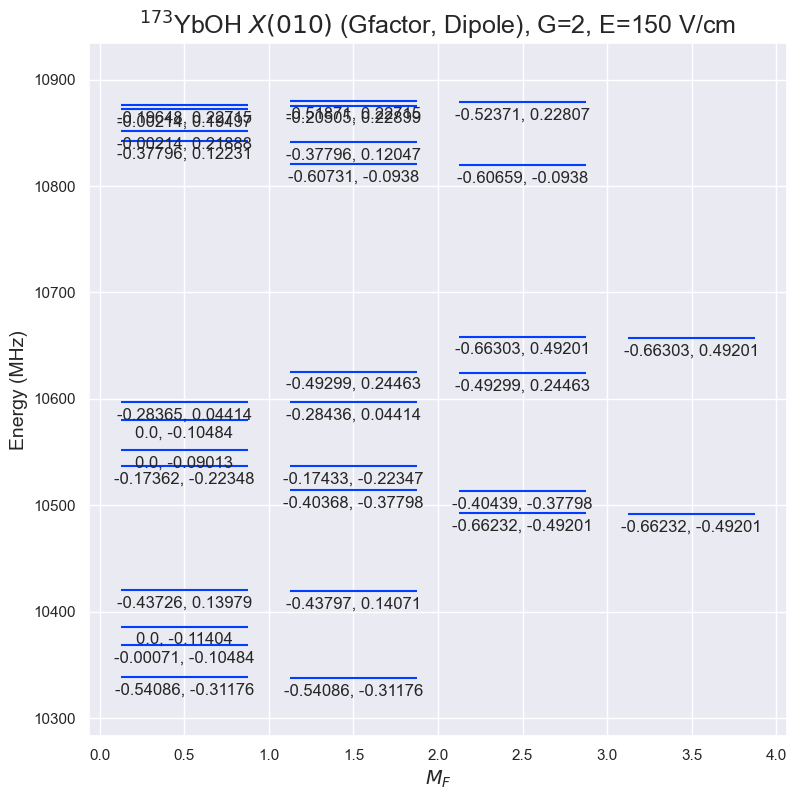

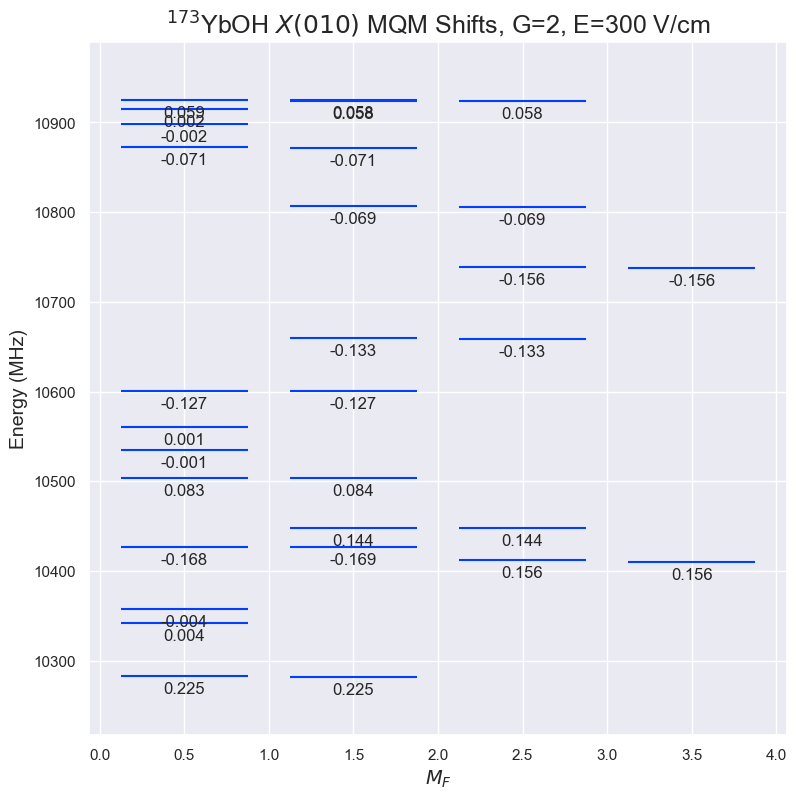

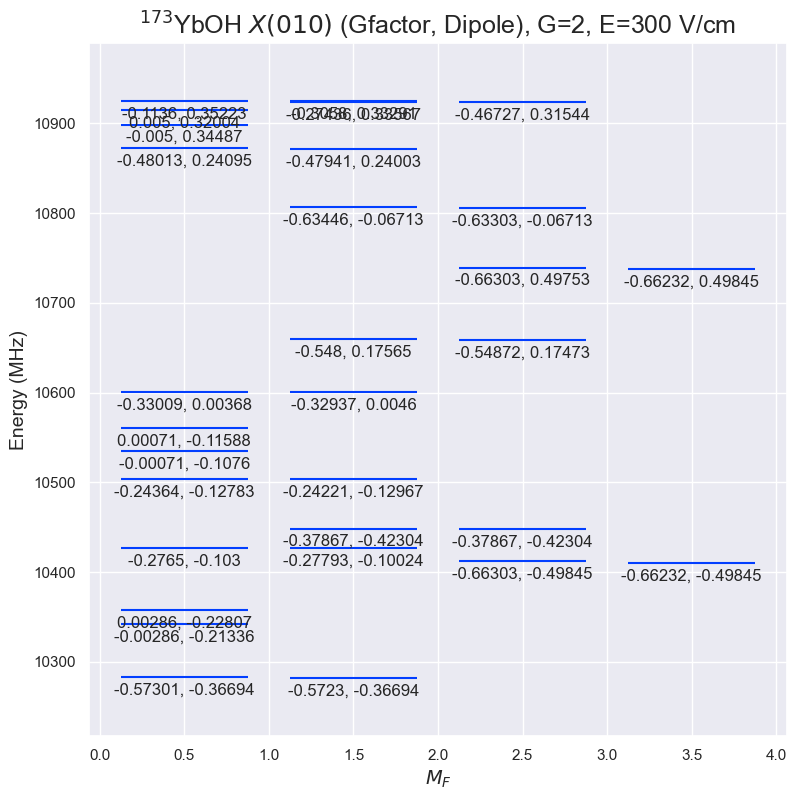

In [19]:
G0 = 2
for E0 in [0,50,100,150,300]:
    X010.display_PTV(E0,1e-4,'MQM',idx=X010.select_q({'G':G0}),round=3)
#     plt.ylim(10300,10500)
    plt.title(X010.state_str + ' MQM Shifts, G={}, E={} V/cm'.format(G0,E0),fontsize=18)

    X010.display_g_D_eff(E0,1e-4,idx=X010.select_q({'G':G0}),round=5)
    # plt.ylim(10300,10500)
    plt.title(X010.state_str + ' (Gfactor, Dipole), G={}, E={} V/cm'.format(G0,E0),fontsize=18)

In [20]:
[str(x) for x in [0,1]]  # port: bare generator expression was a SyntaxError

['0', '1']

In [21]:
type(X010.g_eff_E[0])

numpy.ndarray

In [22]:
str(np.array(list(zip(X010.g_eff_E[0],X010.g_eff_E[0]*2)))[0]).strip('[]').replace(' ',',')

'0.2715,0.543,'

Text(0.5, 1.0, '$^{173}$YbOH ${X}({010})$ MQM Shifts, G=3, E=650 V/cm')

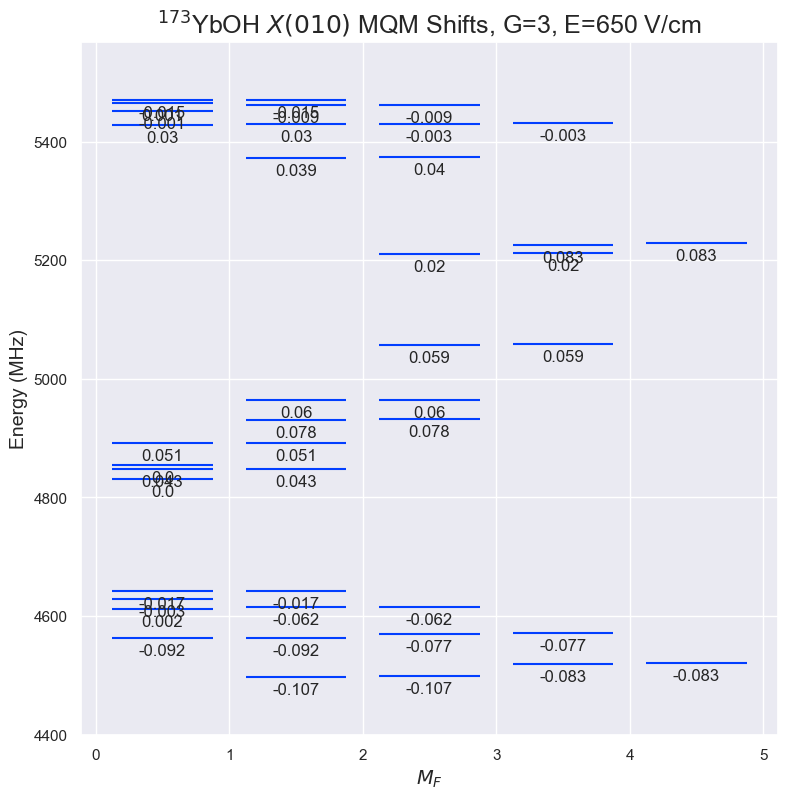

In [23]:
E0 = 650
G0 = 3
X010.display_PTV(E0,1e-4,'MQM',idx=X010.select_q({'G':G0,'F1':[2,3,4]}),round=3)
# plt.ylim(10300,1050a0)
plt.title(X010.state_str + ' MQM Shifts, G={}, E={} V/cm'.format(G0,E0),fontsize=18)

(-2.5, 2.5)

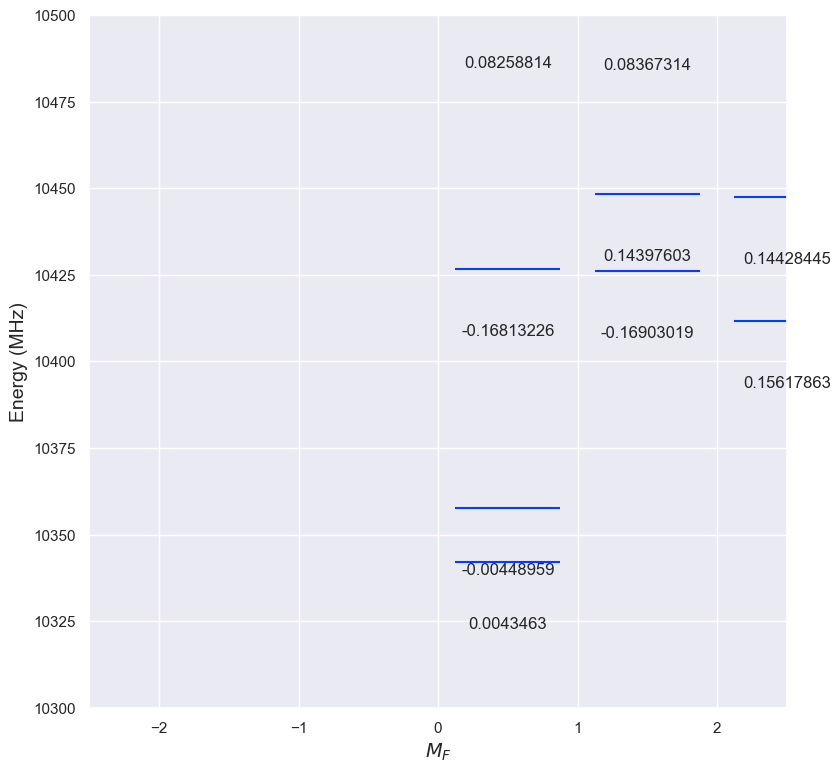

In [24]:
X010.display_PTV(300,1e-3,'MQM',idx=X010.select_q({'G':2}))
plt.ylim(10300,10500)
plt.xlim(-2.5,2.5)

In [25]:
B0 = 9
E0 = 150
evals, evecs = X010.eigensystem(E0,B0,order=True,method='torch')
M0_idx = X010.select_q({'N':1,})
print(M0_idx)
print('\n')
for i in M0_idx:
    display(Latex('$E = '+str(np.round(X010.evals0[i],4))+r'\:\mathrm{MHz}$'))
    # port: decoupled-basis display disabled. convert_evecs('decoupled') from case bBS uses the single-nucleus
    # decoupler (molecule_library_class.py 'b_decoupled', commented 'WILL NOT WORK for case bBS'): KeyError 'M_I'.
    # print('Decoupled:')
    # display(Latex(X010.gen_state_str(i,basis='decoupled',thresh=0.05,label_q=['K','M_N','M_S','M_I','M_F'],round=4)))
#     print('Case A:')
#     display(Latex(X010.gen_state_str(i,basis='aBJ',thresh=0.05,label_q=['K','J','F','Sigma','P','M'],round=4)))
    print('Case B:')
    print('Parity=',X010.parities[i])
    display(Latex(X010.gen_state_str(i,thresh=0.0005,round=4)))
    print('\n')

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71]




<IPython.core.display.Latex object>

Case B:
Parity= -1.0


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Case B:
Parity= -1.0


... (207 outputs left out)

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Case B:
Parity= 1.0


<IPython.core.display.Latex object>

In [26]:
def l2s(inputlist):
      """
      Convert a flatten list to a list of slices:
      test = [0,2,3,4,5,6,12,99,100,101,102,13,14,18,19,20,25]
      list_to_slices(test)
      -> [(0, 0), (2, 6), (12, 14), (18, 20), (25, 25), (99, 102)]
      """
      inputlist.sort()
      pointers = np.where(np.diff(inputlist) > 1)[0]
      pointers = zip(np.r_[0, pointers+1], np.r_[pointers, len(inputlist)-1])
      slices = [(inputlist[i], inputlist[j]+1) for i, j in pointers]
      return slices

In [27]:
from tabulate import tabulate

In [28]:
Bz = np.linspace(1e-6,40,1000)
Ez = np.linspace(0,500,1000)

We can display a plot of the energy levels at arbitray field. (The code does not handle parity labeling well, so I am leaving out L for zero field.)

We can also look at PT violating shifts. Here, we consider the EDM shifts as a function of E field. 

We can look specifically at the upper and lower Stark manifolds at a given field value too.

In [29]:
np.log10(-0.01)

C:\Users\Arian\AppData\Local\Temp\ipykernel_54172\3007267384.py:1: RuntimeWarning: invalid value encountered in log10
  np.log10(-0.01)


nan